In [1]:
print("Hello! My First Data Science Project")

name = "Nageshwaran"

print("Project Developer:", name)
print("Project: Customer Churn Prediction")

Hello! My First Data Science Project
Project Developer: Nageshwaran
Project: Customer Churn Prediction


In [5]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nAll Data Science libraries are working!")

Pandas: 2.2.2
NumPy: 2.0.0
Scikit-learn: 1.9.1

All Data Science libraries are working!


In [7]:
import pandas as pd

# Dataset URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 7043
Number of Columns: 21


In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [11]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [14]:
import os

os.makedirs("datas", exist_ok=True)

df.to_csv("datas/customer_churn.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [15]:
os.path.exists("datas/customer_churn.csv")

True

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [18]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [20]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [21]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [22]:
print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


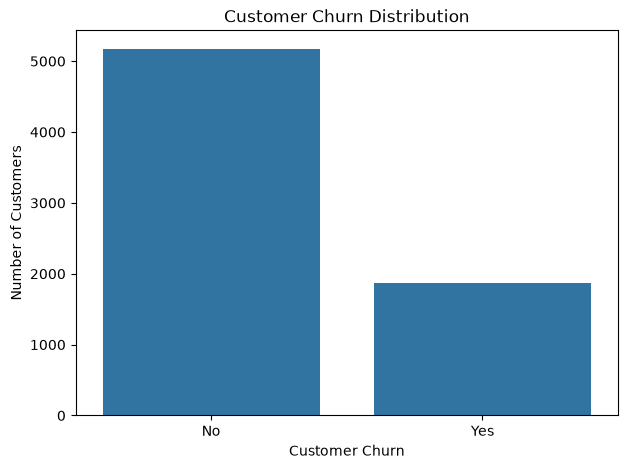

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [24]:
df_clean = df.copy()

print("Backup created successfully!")

Backup created successfully!


In [25]:
df_clean.drop("customerID", axis=1, inplace=True)

print("Customer ID removed!")

Customer ID removed!


In [26]:
print(df_clean["TotalCharges"].dtype)

object


In [27]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print("TotalCharges converted successfully!")
print(df_clean["TotalCharges"].dtype)

TotalCharges converted successfully!
float64


In [28]:
missing_values = df_clean.isnull().sum()

print(missing_values[missing_values > 0])

TotalCharges    11
dtype: int64


In [29]:
df_clean[
    df_clean["TotalCharges"].isnull()
][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [30]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing values handled!")
print("Remaining missing values:", df_clean.isnull().sum().sum())

Missing values handled!
Remaining missing values: 0


In [31]:
print("Duplicate records:", df_clean.duplicated().sum())

Duplicate records: 22


In [32]:
df_clean.drop_duplicates(inplace=True)

print("Duplicate records removed!")
print("Updated dataset shape:", df_clean.shape)

Duplicate records removed!
Updated dataset shape: (7021, 20)


In [33]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   object 
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   object 
 3   Dependents        7021 non-null   object 
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   object 
 6   MultipleLines     7021 non-null   object 
 7   InternetService   7021 non-null   object 
 8   OnlineSecurity    7021 non-null   object 
 9   OnlineBackup      7021 non-null   object 
 10  DeviceProtection  7021 non-null   object 
 11  TechSupport       7021 non-null   object 
 12  StreamingTV       7021 non-null   object 
 13  StreamingMovies   7021 non-null   object 
 14  Contract          7021 non-null   object 
 15  PaperlessBilling  7021 non-null   object 
 16  PaymentMethod     7021 non-null   object 
 17  

In [34]:
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print("Total rows and columns:", df_clean.shape)

Missing values: 0
Duplicate records: 0
Total rows and columns: (7021, 20)


In [35]:
import os

os.makedirs("datas", exist_ok=True)

df_clean.to_csv(
    "datas/customer_churn_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Data Cleaning and Preprocessing

### Objective
Prepare the raw telecommunications customer dataset for exploratory analysis and machine learning.

### Steps performed

1. Created a backup of the original dataset.
2. Removed the customerID column because it is an identifier rather than a useful predictive feature.
3. Converted TotalCharges from object to numeric format.
4. Identified missing values in TotalCharges.
5. Replaced missing TotalCharges values with zero for customers with zero tenure.
6. Checked and removed duplicate records.
7. Verified the cleaned dataset for missing values and duplicates.

### Tools Used
- Python
- Pandas
- NumPy

### Output
A cleaned dataset saved as `customer_churn_cleaned.csv`.

### Business Relevance
Data cleaning improves data quality and prepares customer information for reliable statistical analysis and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv("datas/customer_churn_cleaned.csv")

sns.set_theme(style="whitegrid")

print("Dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)

df_clean.head()

Dataset loaded successfully!
Dataset shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
churn_counts = df_clean["Churn"].value_counts()

print(churn_counts)

Churn
No     5164
Yes    1857
Name: count, dtype: int64


In [3]:
churn_percentage = (
    df_clean["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

Churn
No     73.55
Yes    26.45
Name: proportion, dtype: float64


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/churn_distribution.png'

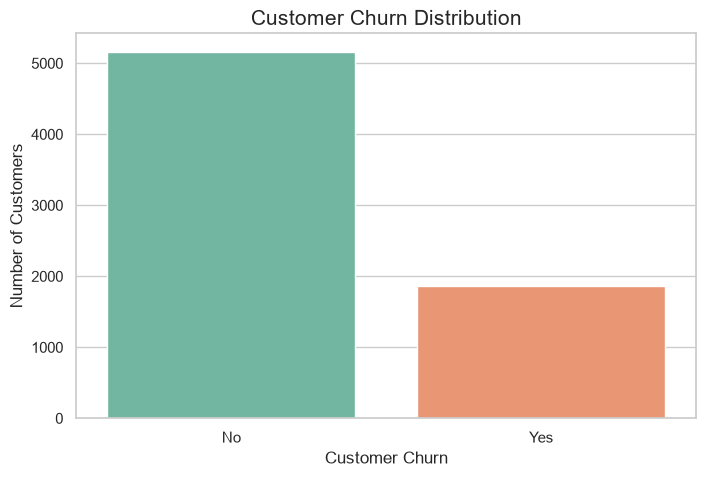

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=15)
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.savefig("outputs/churn_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/churn_by_contract.png'

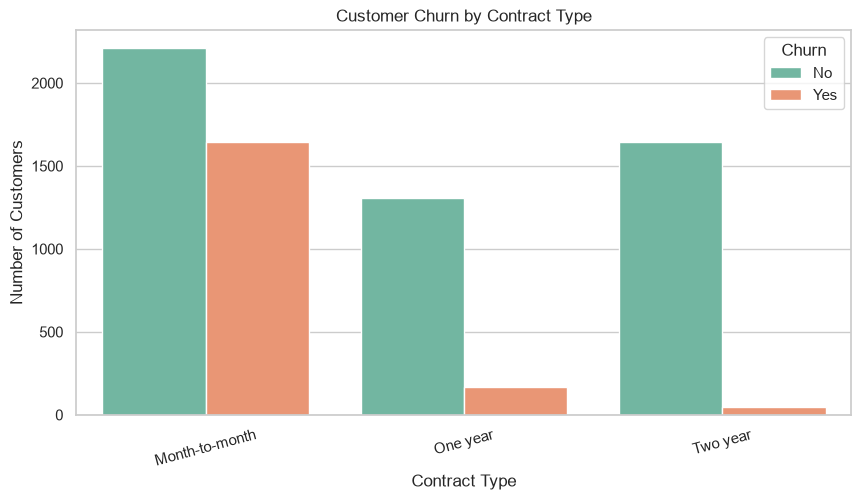

In [5]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.savefig("outputs/churn_by_contract.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [6]:
import os

os.makedirs("outputs", exist_ok=True)

print("Outputs folder is ready!")
print("Current location:", os.getcwd())

Outputs folder is ready!
Current location: C:\Users\nages\OneDrive\Desktop\Data_Science_Portfolio


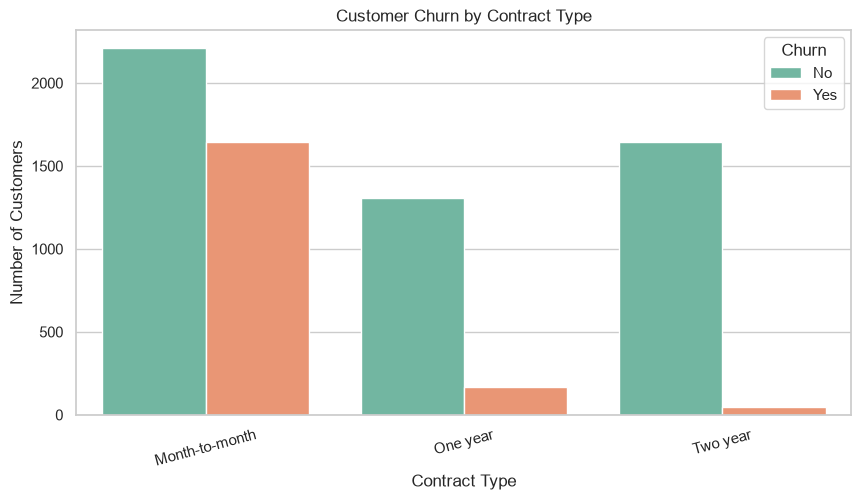

In [7]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.savefig(
    "outputs/churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
print(os.listdir("outputs"))

['churn_by_contract.png']


In [9]:
os.makedirs("datas", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

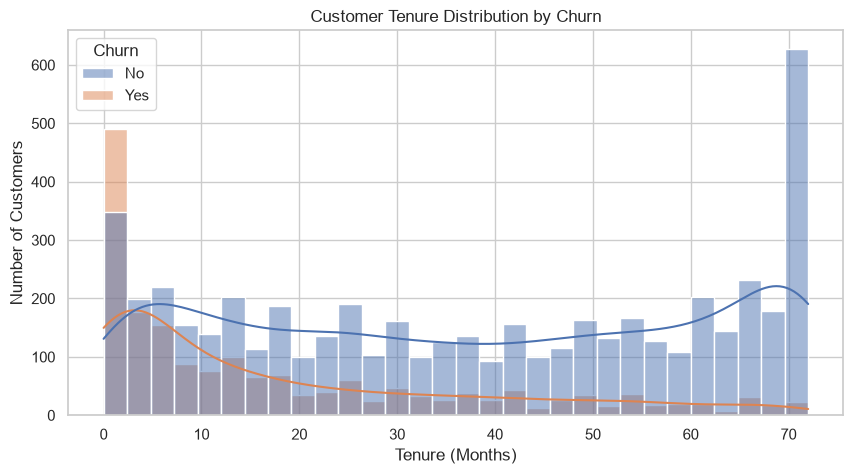

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.savefig(
    "outputs/churn_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
tenure_analysis = df_clean.groupby(
    "Churn"
)["tenure"].mean()

print(tenure_analysis)

Churn
No     37.640782
Yes    18.088853
Name: tenure, dtype: float64


### Customer Tenure Analysis

**Objective:** Analyze the relationship between customer tenure and churn.

**Methodology:**
- Created a tenure distribution histogram.
- Compared tenure patterns between churned and retained customers.
- Calculated average tenure for both customer groups.

**Business Relevance:**
Understanding customer tenure helps identify whether newer customers require additional engagement and retention strategies.

**Findings:** Add the actual average tenure values and observations after running the analysis.

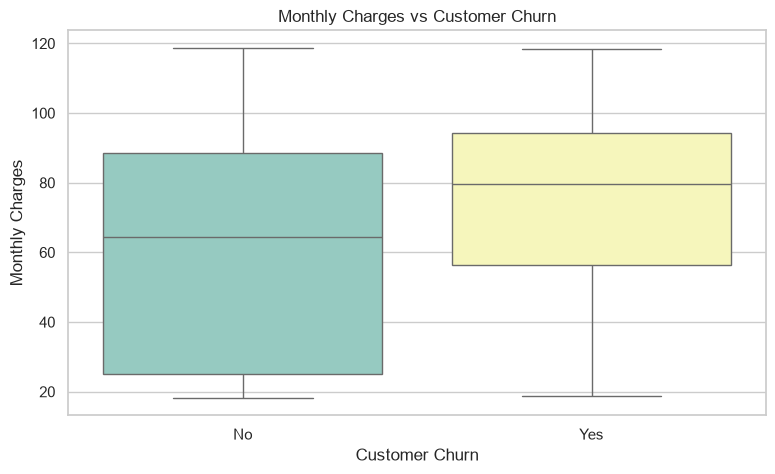

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set3",
    legend=False
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.savefig(
    "outputs/monthly_charges_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
charges_analysis = df_clean.groupby(
    "Churn"
)["MonthlyCharges"].mean()

print("Average Monthly Charges:")
print(charges_analysis)

Average Monthly Charges:
Churn
No     61.344878
Yes    74.604308
Name: MonthlyCharges, dtype: float64


In [14]:
charge_difference = (
    charges_analysis["Yes"] - charges_analysis["No"]
)

print("Difference in average monthly charges:", round(charge_difference, 2))

Difference in average monthly charges: 13.26


### Monthly Charges Analysis

**Objective:** Investigate the relationship between monthly customer charges and churn.

**Methodology:**
- Created a box plot comparing monthly charges.
- Calculated average monthly charges for retained and churned customers.
- Compared the difference between the two customer groups.

**Business Relevance:**
This analysis helps identify whether pricing and monthly spending patterns may be associated with customer churn.

**Findings:** Add actual average charges and observations after running the analysis.

In [15]:
df_clean["InternetService"].value_counts()

InternetService
Fiber optic    3090
DSL            2419
No             1512
Name: count, dtype: int64

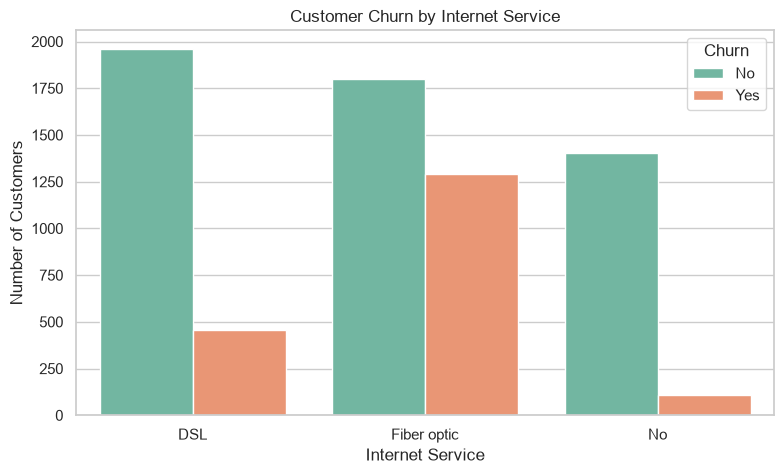

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="InternetService",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.savefig(
    "outputs/churn_by_internet.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
internet_churn = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(internet_churn.round(2))

Churn,No,Yes
InternetService,,
DSL,81.11,18.89
Fiber optic,58.22,41.78
No,92.79,7.21


In [18]:
highest_churn = internet_churn["Yes"].idxmax()

highest_percentage = internet_churn["Yes"].max()

print("Highest churn category:", highest_churn)
print("Churn percentage:", round(highest_percentage, 2), "%")

Highest churn category: Fiber optic
Churn percentage: 41.78 %


### Internet Service Analysis

**Objective:** Investigate customer churn patterns across different internet service categories.

**Methodology:**
- Examined the distribution of DSL, Fiber optic and No internet service customers.
- Visualized churn counts using a grouped count plot.
- Calculated churn percentages for each internet service category.
- Identified the category with the highest observed churn rate.

**Business Relevance:**
This analysis helps the company identify internet service customer segments that may require further investigation and customer retention strategies.

**Findings:** Add the actual churn percentages and highest churn category from the analysis output.

In [19]:
df_clean["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2359
Mailed check                 1596
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

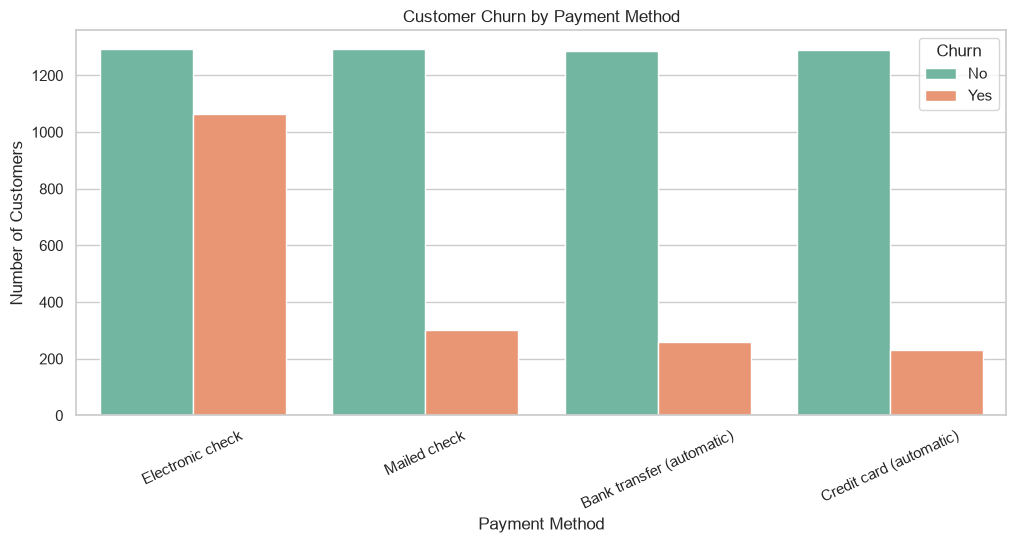

In [20]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df_clean,
    x="PaymentMethod",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)

plt.savefig(
    "outputs/churn_by_payment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
payment_churn = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(payment_churn.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.85,45.15
Mailed check,81.08,18.92


In [22]:
highest_payment_churn = payment_churn["Yes"].idxmax()

print("Highest churn payment method:",
      highest_payment_churn)

print("Churn rate:",
      round(payment_churn["Yes"].max(), 2), "%")

Highest churn payment method: Electronic check
Churn rate: 45.15 %


### Payment Method Analysis

**Objective:** Understand whether customer payment methods are associated with different churn rates.

**Methodology:**
- Examined the distribution of payment methods.
- Compared churn counts across payment categories.
- Calculated the churn percentage for each payment method.
- Identified the payment category with the highest observed churn rate.

**Business Relevance:**
Payment behaviour analysis can help businesses investigate customer payment experiences and potential retention opportunities.

**Findings:** Insert actual results after executing the analysis.

In [23]:
numeric_df = df_clean.select_dtypes(
    include=["int64", "float64"]
)

print(numeric_df.columns.tolist())

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [24]:
numeric_df["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [25]:
correlation = numeric_df.corr()

display(correlation.round(2))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.00,0.02,0.22,0.10,0.15
tenure,0.02,1.00,0.25,0.83,-0.35
MonthlyCharges,0.22,0.25,1.00,0.65,0.19
TotalCharges,0.10,0.83,0.65,1.00,-0.20
Churn,0.15,-0.35,0.19,-0.20,1.00


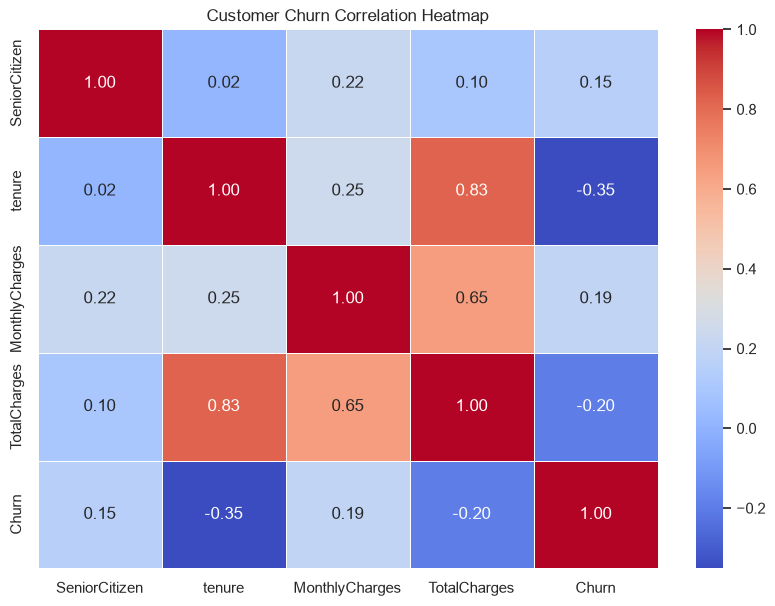

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Churn Correlation Heatmap")

plt.savefig(
    "outputs/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
churn_correlation = correlation["Churn"].sort_values(
    ascending=False
)

print("Correlation with Customer Churn:")
print(churn_correlation)

Correlation with Customer Churn:
Churn             1.000000
MonthlyCharges    0.194508
SeniorCitizen     0.151619
TotalCharges     -0.197198
tenure           -0.351508
Name: Churn, dtype: float64


In [28]:
total_customers = len(df_clean)

churned_customers = (
    df_clean["Churn"] == "Yes"
).sum()

retained_customers = (
    df_clean["Churn"] == "No"
).sum()

churn_rate = (
    churned_customers / total_customers
) * 100

average_monthly_charge = df_clean["MonthlyCharges"].mean()

print("CUSTOMER CHURN BUSINESS REPORT")
print("--------------------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Average Monthly Charges:",
      round(average_monthly_charge, 2))

CUSTOMER CHURN BUSINESS REPORT
--------------------------------
Total Customers: 7021
Churned Customers: 1857
Retained Customers: 5164
Churn Rate: 26.45 %
Average Monthly Charges: 64.85


# Exploratory Data Analysis – Final Report

## 1. Project Objective
Analyze telecommunications customer data to identify patterns and factors associated with customer churn.

## 2. Dataset Overview
- Total records: 7,043 (before any duplicate removal)
- Original features: 21
- Target variable: Churn

## 3. Analysis Performed
- Customer churn distribution
- Gender-based analysis
- Contract type analysis
- Customer tenure analysis
- Monthly charges analysis
- Internet service analysis
- Payment method analysis
- Numerical correlation analysis

## 4. Key Business Metrics
- Total customers: [Insert actual value]
- Churned customers: [Insert actual value]
- Retained customers: [Insert actual value]
- Overall churn rate: [Insert actual percentage]
- Average monthly charges: [Insert actual value]

## 5. Business Insights
Add observations from your actual charts and analysis tables.

Investigate:
- Which contract category has the highest churn rate?
- Which internet service category has the highest churn rate?
- Which payment method has the highest churn rate?
- How does average tenure differ between churned and retained customers?
- How do monthly charges differ between customer groups?

## 6. Business Recommendations
- Investigate retention strategies for high-churn customer segments.
- Improve onboarding and customer engagement.
- Review pricing and service experiences.
- Investigate payment-related customer difficulties.
- Monitor customer churn indicators regularly.

## 7. Conclusion
EDA helped identify customer behaviour patterns and provided a foundation for developing a machine learning model to predict customer churn.`

In [29]:
import pandas as pd
import numpy as np

df_clean = pd.read_csv("datas/customer_churn_cleaned.csv")

print("Dataset loaded successfully!")
print(df_clean.shape)

Dataset loaded successfully!
(7021, 20)


In [30]:
X = df_clean.drop("Churn", axis=1)

y = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7021, 19)
Target shape: (7021,)


In [31]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [32]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(
    X[categorical_features]
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(
        categorical_features
    )
)

display(encoded_df.head())

,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    X[numeric_features]
)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=numeric_features
)

display(scaled_df.head())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,-0.440508,-1.282728,-1.164135,-0.995686
1,-0.440508,0.062387,-0.262811,-0.175262
2,-0.440508,-1.241967,-0.365914,-0.961142
3,-0.440508,0.510759,-0.750058,-0.196769
4,-0.440508,-1.241967,0.194503,-0.941951


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (5616, 19)
Testing data: (1405, 19)
Training target: (5616,)
Testing target: (1405,)


# Feature Engineering and Data Preparation

## Objective
Prepare customer information for machine learning model development.

## Steps Performed

1. Loaded the cleaned customer dataset.
2. Separated independent variables (X) and dependent variable (y).
3. Converted the churn target into binary values.
4. Identified numerical and categorical features.
5. Explored One-Hot Encoding for categorical variables.
6. Explored StandardScaler for numerical variables.
7. Split the dataset into training and testing subsets.

## Data Split
- Training: 80%
- Testing: 20%

## Data Leakage Prevention
The final machine learning implementation uses a Scikit-learn Pipeline and ColumnTransformer to fit preprocessing transformations only on training data.

## Tools Used
- Pandas
- NumPy
- Scikit-learn

## Conclusion
The dataset is prepared for machine learning classification using appropriate feature preprocessing and train-test separation.

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np

In [37]:
# Identify column types from training data

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()


# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [38]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [39]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [40]:
lr_predictions = logistic_pipeline.predict(X_test)

lr_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression Predictions:")
print(lr_predictions[:10])

Logistic Regression Predictions:
[1 1 1 0 0 1 0 1 0 0]


In [41]:
rf_predictions = random_forest_pipeline.predict(X_test)

rf_probabilities = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

print("Random Forest Predictions:")
print(rf_predictions[:10])

Random Forest Predictions:
[1 1 1 0 0 0 0 1 0 0]


In [42]:
models = {
    "Logistic Regression": (
        lr_predictions,
        lr_probabilities
    ),
    "Random Forest": (
        rf_predictions,
        rf_probabilities
    )
}

results = []

for name, (predictions, probabilities) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.742,0.508,0.780,0.615,0.840
1,Random Forest,0.764,0.540,0.742,0.625,0.839


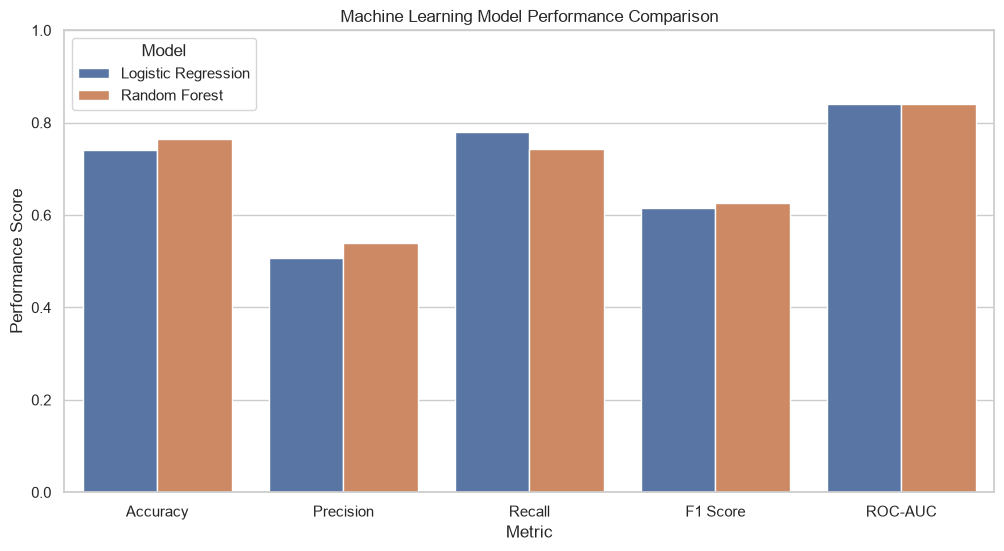

In [43]:
results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylim(0, 1)
plt.ylabel("Performance Score")

plt.savefig(
    "outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Not Churned", "Churned"]
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

 Not Churned       0.90      0.73      0.81      1033
     Churned       0.51      0.78      0.62       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.76      1405



In [45]:
print("RANDOM FOREST REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Not Churned", "Churned"]
))

RANDOM FOREST REPORT
              precision    recall  f1-score   support

 Not Churned       0.89      0.77      0.83      1033
     Churned       0.54      0.74      0.63       372

    accuracy                           0.76      1405
   macro avg       0.72      0.76      0.73      1405
weighted avg       0.80      0.76      0.77      1405



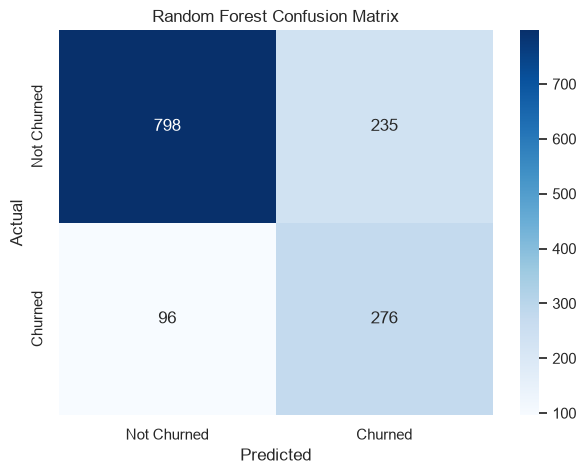

In [46]:
cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    "outputs/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
best_model_name = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

print("Best model based on ROC-AUC:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = logistic_pipeline
else:
    best_model = random_forest_pipeline

Best model based on ROC-AUC: Logistic Regression


In [48]:
import joblib
import os

os.makedirs("outputs", exist_ok=True)

joblib.dump(
    logistic_pipeline,
    "outputs/logistic_regression_model.pkl"
)

joblib.dump(
    random_forest_pipeline,
    "outputs/random_forest_model.pkl"
)

joblib.dump(
    best_model,
    "outputs/best_customer_churn_model.pkl"
)

print("All models saved successfully!")

All models saved successfully!


# Machine Learning Model Development and Evaluation

## Objective
Develop classification models to predict customer churn using telecommunications customer data.

## Algorithms Implemented

### 1. Logistic Regression
Used as a baseline binary classification algorithm to estimate customer churn probability.

### 2. Random Forest Classifier
Used an ensemble of decision trees to identify customer churn patterns.

## Data Preprocessing
- Numerical feature scaling using StandardScaler.
- Categorical feature encoding using OneHotEncoder.
- Missing-value handling using SimpleImputer.
- Preprocessing integrated with Scikit-learn Pipeline.

## Model Training
- Training dataset: 80%
- Testing dataset: 20%
- Random state: 42
- Class imbalance handling: Balanced class weights.

## Model Evaluation
Both models were evaluated using:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

## Model Comparison
Actual model performance metrics are recorded in the model comparison results table.

## Best Model
[Insert the selected model based on evaluation results.]

## Conclusion
Two machine learning classification algorithms were developed and evaluated to predict customer churn. Their performance was compared to identify a suitable model for customer retention analysis.

In [50]:
# Get the trained Random Forest model
rf_model = random_forest_pipeline

# Extract feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance values
importance_values = rf_model.named_steps[
    "classifier"
].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
1,num__tenure,0.132490
36,cat__Contract_Month-to-month,0.110397
3,num__TotalCharges,0.105856
2,num__MonthlyCharges,0.078118
38,cat__Contract_Two year,0.062579
18,cat__OnlineSecurity_No,0.055136
16,cat__InternetService_Fiber optic,0.049750
27,cat__TechSupport_No,0.044993
43,cat__PaymentMethod_Electronic check,0.033566
21,cat__OnlineBackup_No,0.017140


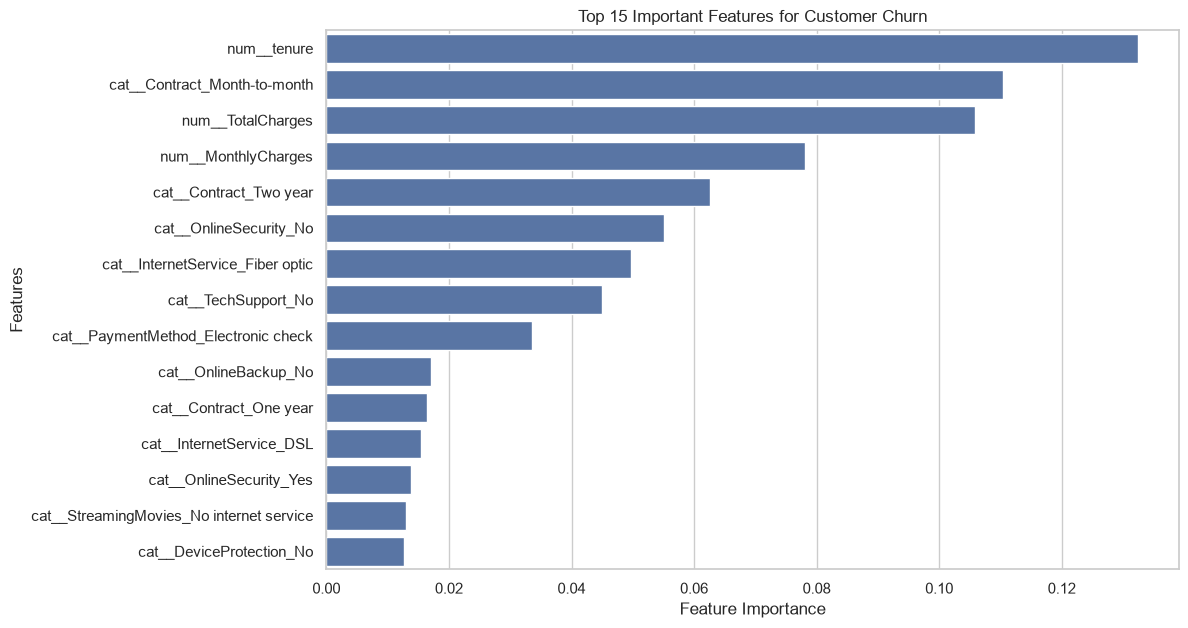

In [51]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.savefig(
    "outputs/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
importance_df.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

print("Feature importance results saved!")

Feature importance results saved!


In [53]:
new_customer = {
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.0,
    "TotalCharges": 190.0
}

new_customer_df = pd.DataFrame([new_customer])

display(new_customer_df)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,95.0,190.0


In [54]:
prediction = random_forest_pipeline.predict(
    new_customer_df
)

probability = random_forest_pipeline.predict_proba(
    new_customer_df
)[0][1]

if prediction[0] == 1:
    print("Prediction: Customer is likely to churn")
else:
    print("Prediction: Customer is likely to stay")

print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Customer is likely to churn
Churn Probability: 84.16 %


In [55]:
test_customers = pd.DataFrame([
    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 2,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 95.0,
        "TotalCharges": 190.0
    },
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "Yes",
        "StreamingMovies": "Yes",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 75.0,
        "TotalCharges": 4500.0
    }
])

# Generate predictions
predictions = random_forest_pipeline.predict(test_customers)

probabilities = random_forest_pipeline.predict_proba(
    test_customers
)[:, 1]

# Create results table
prediction_results = pd.DataFrame({
    "Customer": ["Customer 1", "Customer 2"],
    "Prediction": [
        "Likely to Churn" if p == 1 else "Likely to Stay"
        for p in predictions
    ],
    "Churn Probability (%)": (
        probabilities * 100
    ).round(2)
})

display(prediction_results)

,Customer,Prediction,Churn Probability (%)
0,Customer 1,Likely to Churn,84.16
1,Customer 2,Likely to Stay,2.46


In [56]:
test_customers = pd.DataFrame([
    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 2,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 95.0,
        "TotalCharges": 190.0
    },
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "Yes",
        "StreamingMovies": "Yes",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 75.0,
        "TotalCharges": 4500.0
    }
])

# Generate predictions
predictions = random_forest_pipeline.predict(test_customers)

probabilities = random_forest_pipeline.predict_proba(
    test_customers
)[:, 1]

# Create results table
prediction_results = pd.DataFrame({
    "Customer": ["Customer 1", "Customer 2"],
    "Prediction": [
        "Likely to Churn" if p == 1 else "Likely to Stay"
        for p in predictions
    ],
    "Churn Probability (%)": (
        probabilities * 100
    ).round(2)
})

display(prediction_results)

,Customer,Prediction,Churn Probability (%)
0,Customer 1,Likely to Churn,84.16
1,Customer 2,Likely to Stay,2.46


In [57]:
prediction_results.to_csv(
    "outputs/new_customer_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


# Feature Importance and New Customer Prediction

## Objective
Identify important features associated with model predictions and demonstrate customer churn prediction using new customer records.

## Feature Importance Analysis
- Extracted feature importance scores from the trained Random Forest model.
- Ranked features according to their importance.
- Created a feature importance visualization.
- Exported feature importance scores into CSV format.

## New Customer Prediction
Created hypothetical customer records and passed them through the trained Random Forest pipeline.

## Prediction Outputs
- Predicted customer churn class.
- Estimated churn probability.
- Generated predictions for multiple customers.

## Business Applications
- Identify customers who may be at risk of leaving.
- Support customer retention strategies.
- Help businesses prioritize customer engagement.
- Assist data-driven decision-making.

## Limitations
- Predictions are based on historical customer data.
- Model probabilities are estimates, not guarantees.
- Feature importance does not establish causality.
- Model performance should be monitored when applied to real-world data.

## Conclusion
The trained machine learning model was successfully used to identify important predictive features and generate churn predictions for hypothetical new customer records.`

In [58]:
import os

os.makedirs("datas", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("docs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [59]:
readme_content = """
# Customer Churn Prediction

## 1. Project Overview
This project predicts whether a telecom customer is likely to leave
the company using machine learning techniques.

## 2. Business Problem
Customer churn affects company revenue and customer retention.
The objective is to identify customers who are likely to discontinue
their services so that businesses can take preventive action.

## 3. Dataset
Dataset: IBM Telco Customer Churn

The dataset contains customer information, services, contract details,
billing information and the target variable Churn.

## 4. Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## 5. Project Workflow
1. Data collection
2. Data inspection
3. Data cleaning
4. Exploratory Data Analysis (EDA)
5. Feature engineering
6. Data preprocessing
7. Model training
8. Model evaluation
9. Feature importance
10. Customer churn prediction

## 6. Machine Learning Models
- Logistic Regression
- Random Forest Classifier

## 7. Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

## 8. Project Outputs
The outputs folder contains trained models, visualisations,
feature importance results and customer prediction results.

## 9. Business Impact
The model can help businesses identify customers at risk of leaving
and support targeted customer retention strategies.

## 10. Author
Nageshwaran S
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [60]:
print(os.path.exists("README.md"))

True


In [61]:
documentation = """
# CUSTOMER CHURN PREDICTION
## Technical Project Documentation

### 1. Project Objective
To develop a machine learning system that predicts whether a
telecommunication customer is likely to leave the company.

### 2. Business Understanding
Customer churn results in revenue loss and increased customer
acquisition costs. Predicting potential churn helps businesses
take preventive retention measures.

### 3. Dataset Description
Dataset: IBM Telco Customer Churn

Target variable: Churn
- Yes: Customer left the company
- No: Customer continued the service

The dataset includes customer demographics, subscribed services,
contract information and billing details.

### 4. Data Cleaning
- Removed the customerID column.
- Converted TotalCharges into numeric format.
- Handled missing TotalCharges values.
- Checked for duplicate records.

### 5. Exploratory Data Analysis
Analysed:
- Overall customer churn distribution.
- Churn by contract type.
- Churn by internet service.
- Churn by payment method.
- Customer tenure.
- Monthly charges.
- Numerical feature correlations.

### 6. Feature Engineering and Preprocessing
- Separated independent and target variables.
- Converted churn labels into binary values.
- Identified numerical and categorical features.
- Applied StandardScaler to numerical features.
- Applied OneHotEncoder to categorical features.
- Split data into training and testing sets.

### 7. Machine Learning Models
Model 1: Logistic Regression
Model 2: Random Forest Classifier

### 8. Model Evaluation
Evaluation metrics:
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

Actual model results will be added after reviewing the
evaluation output from the notebook.

### 9. Feature Importance
Random Forest feature importance was used to identify
features that contributed to model predictions.

### 10. Customer Prediction
The trained model was tested using hypothetical customer
profiles to estimate their churn probability.

### 11. Business Applications
- Identify customers at risk of leaving.
- Support targeted retention campaigns.
- Help customer relationship management teams.
- Improve customer retention strategies.

### 12. Limitations
- Predictions are based on historical dataset patterns.
- Model probabilities are estimates, not guarantees.
- Further validation is required before real-world deployment.

### 13. Future Enhancements
- Hyperparameter tuning.
- Model explainability using SHAP.
- Probability calibration.
- Deployment using Streamlit or Flask.
- Integration with a live customer database.

### 14. Conclusion
This project demonstrates an end-to-end machine learning
workflow for customer churn prediction, from data cleaning
and exploratory analysis to model evaluation and prediction.
"""

with open("docs/project_documentation.md", "w", encoding="utf-8") as file:
    file.write(documentation)

print("Project documentation created successfully!")

Project documentation created successfully!


In [62]:
import os

print(os.path.exists("docs/project_documentation.md"))

True


In [63]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
jupyter
"""

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements.strip() + "\n")

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [64]:
with open("requirements.txt", "r") as file:
    print(file.read())

pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
jupyter



In [65]:
# Check which trained model variables are available
for name in globals():
    if "pipeline" in name.lower() or "model" in name.lower():
        print(name)

Pipeline
logistic_pipeline
random_forest_pipeline
models
best_model_name
best_model
rf_model


In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Predictions from both models
logistic_predictions = logistic_pipeline.predict(X_test)
random_forest_predictions = random_forest_pipeline.predict(X_test)

# Churn probabilities
logistic_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
random_forest_probabilities = random_forest_pipeline.predict_proba(X_test)[:, 1]

# Calculate performance metrics
results = []

for name, predictions, probabilities in [
    ("Logistic Regression", logistic_predictions, logistic_probabilities),
    ("Random Forest", random_forest_predictions, random_forest_probabilities)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

performance_df = pd.DataFrame(results)

performance_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7416,0.5079,0.7796,0.6151,0.8398
1,Random Forest,0.7644,0.5401,0.7419,0.6251,0.8394


In [67]:
performance_df.to_csv(
    "outputs/model_performance.csv",
    index=False
)

print("Model performance saved successfully!")

Model performance saved successfully!


In [68]:
import os

for root, dirs, files in os.walk("."):
    # Ignore Jupyter's temporary checkpoint folder
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    level = root.count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

./
    Customer_Churn_Prediction.ipynb
    README.md
    requirements.txt
    Customer_Churn_Prediction/
        datas/
        outputs/
    datas/
        customer_churn.csv
        customer_churn_cleaned.csv
    docs/
        project_documentation.md
    outputs/
        best_customer_churn_model.pkl
        churn_by_contract.png
        churn_by_internet.png
        churn_by_payment.png
        churn_by_tenure.png
        correlation_heatmap.png
        feature_importance.csv
        feature_importance.png
        logistic_regression_model.pkl
        model_comparison.png
        model_performance.csv
        monthly_charges_churn.png
        new_customer_predictions.csv
        random_forest_confusion_matrix.png
        random_forest_model.pkl


In [69]:
gitignore_content = """
# Python cache files
__pycache__/
*.pyc

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/

# System files
.DS_Store
Thumbs.db

# Environment variables and secrets
.env
"""

with open(".gitignore", "w", encoding="utf-8") as file:
    file.write(gitignore_content.strip() + "\n")

print(".gitignore created successfully!")

.gitignore created successfully!


In [70]:
with open(".gitignore", "r") as file:
    print(file.read())

# Python cache files
__pycache__/
*.pyc

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/

# System files
.DS_Store
Thumbs.db

# Environment variables and secrets
.env

